# CME538 - Introduction to Data Science

## Assignment 9 - Unsupervised Learning

### Learning Objectives

After completing this assignment, you should be able to:

- Explain the purpose of unsupervised learning and distinguish it from supervised learning.
- Apply Principal Component Analysis (PCA) to transform multivariate data.
- Interpret principal components and explained variance.
- Use PCA for dimensionality reduction and visualization.
- Reshape time-series data into features suitable for unsupervised learning.
- Apply k-means clustering to identify groups in unlabeled data.
- Use inertia and the elbow method to investigate an appropriate number of clusters.
- Compare clustering approaches and recognize when k-means may not be appropriate.
- Interpret clusters using patterns in the original data.
- Build a reproducible unsupervised learning workflow from data preparation through interpretation.

### Marking Breakdown

| Question | Marks |
|---|---:|
| Question 1a | 1 |
| Question 1b | 1 |
| Question 1c | 1 |
| Question 2a | 1 |
| Question 2b | 1 |
| Question 2c | 1 |
| Question 2d | 1 |
| Question 2e | 1 |
| Question 2f | 1 |
| Question 2g | 1 |
| Question 2h | 1 |
| Question 2i | 1 |
| Question 2j | 3 |
| Code quality | 3 |
| **Total** | **18** |

### Code Quality

Code quality will be assessed across the complete notebook.

| Level | Points | Description |
|---|---:|---|
| **Developing** | 1 | Code produces the required results but may be difficult to follow, unnecessarily repetitive, poorly organized, or include excessive output. |
| **Competent** | 2 | Code is organized and readable, uses appropriate Pandas and scikit-learn operations, and produces concise, relevant outputs. |
| **Strong** | 3 | Code is clear, concise, well organized, and reproducible; uses Pandas and scikit-learn effectively; avoids unnecessary operations and output; and executes successfully from beginning to end. |

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

# Configure notebook plots
%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")

# Install using pip if any module is missing from your environment

# Overview

Imagine that you are working as a data scientist with datasets that contain many observations and variables, but **no known outcome or target variable**.

Unlike the supervised learning problems you have worked with previously, there is no label telling us what the correct answer should be. Instead, our goal is to discover useful structure and patterns directly from the data.

In this assignment, you will investigate two important **unsupervised learning** techniques:

- **Principal Component Analysis (PCA)** — for reducing the dimensionality of a dataset while preserving as much of its variation as possible; and
- **k-means clustering** — for identifying groups of observations that exhibit similar patterns.

You will first use PCA to explore relationships among variables and represent high-dimensional data using a smaller number of principal components.

You will then analyze bicycle-traffic data from Seattle's Fremont Bridge and use clustering to investigate whether different types of daily travel patterns emerge from the data.

Along the way, you will consider an important question:

> **How can we discover meaningful structure in data when we do not already know the groups or outcomes?**

By the end of the assignment, you will have worked through an unsupervised learning workflow involving data preparation, dimensionality reduction, clustering, model comparison, visualization, and interpretation.

---

# 1. Principal Component Analysis on 3D Data

We will begin with a small three-dimensional dataset so that we can visualize what Principal Component Analysis (PCA) is doing geometrically.

The file `data_3d.csv` contains three numerical variables:

- `x`
- `y`
- `z`

When plotted in three dimensions, the observations form an elongated ellipsoid. Because its shape resembles a surfboard, we will refer to the dataset as `surfboard`.

The important feature of this dataset is that the direction of greatest variation is **not aligned with the original x, y, and z axes**.

PCA will help us find a new coordinate system that better aligns with the directions in which the data vary.

In [2]:
# Load the 3D dataset
surfboard = pd.read_csv("data_3d.csv")

surfboard.head()

,x,y,z
0,0.005605,2.298191,1.746604
1,-1.093255,2.457522,0.170309
2,0.060946,0.473669,-0.003543
3,-1.761945,2.151108,3.132426
4,1.950637,-0.194469,-2.101949


## Visualizing the Original Data

The interactive plot below displays the observations in their original coordinate system.

Rotate the figure and examine the shape from different directions.

You should notice that:

- the data are longest in one direction;
- somewhat narrower in a second direction; and
- relatively thin in the third direction.

These directions do not line up with the original `x`, `y`, and `z` axes.

The colors in the visualization are included only to make it easier to track individual observations as we later transform the data. They do not represent a variable of interest.

In [3]:
def colorize_surfboard_data(data):
    """Add pre-generated colors for visualization only."""
    
    colors = (
        pd.read_csv(
            "surfboard_colors.csv",
            header=None
        )
        .to_numpy()
        .ravel()
    )
    
    colored_data = data.copy()
    colored_data["color"] = colors
    
    return colored_data

In [4]:
fig = px.scatter_3d(
    colorize_surfboard_data(surfboard),
    x="x",
    y="y",
    z="z",
    color="color",
    color_continuous_scale="RdBu",
    range_x=[-10, 10],
    range_y=[-10, 10],
    range_z=[-10, 10],
    title="Surfboard Data in the Original Coordinate System"
)

fig.show()

---

## Question 1a — Center the Data

PCA is performed on data after each feature has been centred around zero.

Calculate the mean of each column in `surfboard` and store the result in:

`surfboard_mean`

Then subtract those means from the original data and store the centred observations in:

`surfboard_centered`

The columns should remain in the order:

`x`, `y`, `z`

After centring, the mean of each column should be approximately zero.

In [5]:
# Question 1a

# Calculate the mean of each feature
surfboard_mean = surfboard.mean()

# Center each feature around zero
surfboard_centered = surfboard - surfboard_mean

surfboard_centered.head()

,x,y,z
0,-0.022232,2.264900,1.766968
1,-1.121093,2.424231,0.190672
2,0.033108,0.440379,0.016820
3,-1.789782,2.117818,3.152790
4,1.922799,-0.227760,-2.081586


In [6]:
# Verification - do not modify

print(
    "Original feature means:"
)

print(
    surfboard_mean.round(3)
)

print(
    "\nCentered feature means:"
)

print(
    surfboard_centered.mean().round(10)
)

Original feature means:
x    0.028
y    0.033
z   -0.020
dtype: float64

Centered feature means:
x    0.0
y    0.0
z    0.0
dtype: float64


---

## Question 1b — Fit PCA

Use scikit-learn's `PCA` class to fit a PCA model to `surfboard_centered`.

Because the dataset contains three original features, compute all three principal components.

Store the fitted PCA object in:

`pca`

In [7]:
# Question 1b

# Create a PCA model with three components
pca = PCA(n_components=3)

# Fit PCA using the centered surfboard data
pca.fit(surfboard_centered)

,n_components,3
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [8]:
# Inspect the amount of variance explained by each component

pca_variance = pd.DataFrame({
    "Principal Component": [
        "PC1",
        "PC2",
        "PC3"
    ],
    "Explained Variance Ratio":
        pca.explained_variance_ratio_
})

pca_variance

,Principal Component,Explained Variance Ratio
0,PC1,0.838508
1,PC2,0.126995
2,PC3,0.034497


---

## Question 1c — Transform the Data into Principal-Component Space

Use the fitted PCA model to transform `surfboard_centered` into principal-component coordinates.

Store the transformed observations in a DataFrame named:

`surfboard_pcs`

with columns:

- `pc1`
- `pc2`
- `pc3`

Preserve the original DataFrame index.

In [9]:
# Question 1c

# Transform the centered data into principal-component space
surfboard_pcs = pd.DataFrame(
    pca.transform(surfboard_centered),
    columns=[
        "pc1",
        "pc2",
        "pc3"
    ],
    index=surfboard.index
)

surfboard_pcs.head()

,pc1,pc2,pc3
0,2.648158,0.851423,0.717483
1,2.183269,1.046819,-1.143508
2,0.294094,0.327062,-0.043034
3,4.105824,-0.817194,0.320874
4,-2.209110,1.784578,0.130938


In [10]:
# Verification - do not modify

print(
    "Correct shape:",
    surfboard_pcs.shape
    == surfboard.shape
)

print(
    "Correct columns:",
    surfboard_pcs.columns.tolist()
    == [
        "pc1",
        "pc2",
        "pc3"
    ]
)

Correct shape: True
Correct columns: True


---

## Visualizing Principal-Component Space

PCA creates a new coordinate system.

The observations themselves have not changed. Instead, the coordinate axes have been rotated so that:

- **PC1** points in the direction of greatest variation;
- **PC2** captures the largest remaining variation while remaining perpendicular to PC1; and
- **PC3** captures the remaining variation while remaining perpendicular to both PC1 and PC2.

For this dataset, we should therefore expect the transformed "surfboard" to appear aligned with the new axes.

In [11]:
fig = px.scatter_3d(
    colorize_surfboard_data(
        surfboard_pcs
    ),
    x="pc1",
    y="pc2",
    z="pc3",
    color="color",
    color_continuous_scale="RdBu",
    range_x=[-10, 10],
    range_y=[-10, 10],
    range_z=[-10, 10],
    title="Surfboard Data in Principal-Component Space"
)

fig.show()

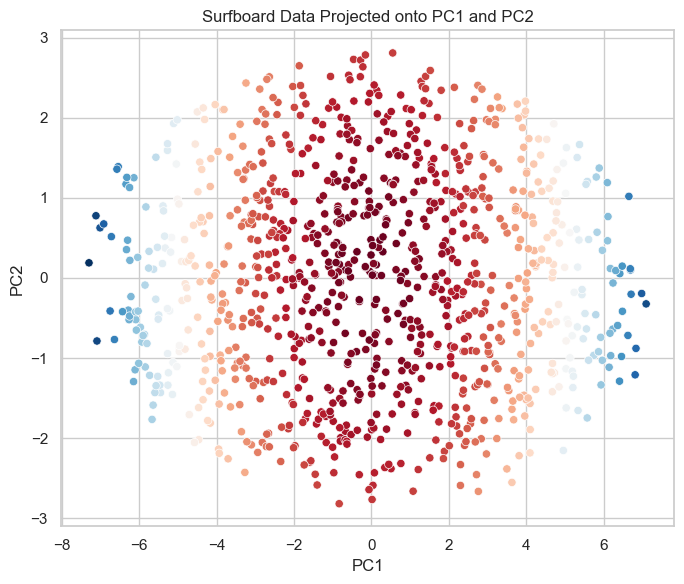

In [12]:
plt.figure(
    figsize=(7, 6)
)

sns.scatterplot(
    data=colorize_surfboard_data(
        surfboard_pcs
    ),
    x="pc1",
    y="pc2",
    hue="color",
    palette="RdBu",
    legend=False
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Surfboard Data Projected onto PC1 and PC2")

plt.tight_layout()
plt.show()

---
# 2. Fremont Bridge Bicycle Traffic

We will now apply unsupervised learning to a real-world dataset.

The Fremont Bridge in Seattle contains automated bicycle counters that record the number of cyclists travelling across the bridge in each direction. The dataset contains **hourly bicycle counts**, giving us a detailed picture of how bicycle activity changes throughout each day.

Suppose you are working with the City of Seattle and want to understand patterns in bicycle traffic.

You do not have predefined labels such as "commuter day", "weekend day", or "low-traffic day." Instead, you want to determine whether these patterns can be discovered directly from the bicycle-count data.

This makes the problem well suited to **unsupervised learning**.

We will use PCA to reduce the dimensionality of daily bicycle-traffic patterns and clustering methods to investigate whether naturally occurring groups of days emerge from the data.

In [13]:
# Load the Fremont Bridge bicycle-count data
bike_data = pd.read_csv(
    "fremont_bridge_bicycle_counter.csv",
    index_col="datetime",
    parse_dates=True
)

bike_data.head()

,total,east,west
datetime,,,
2019-11-01 00:00:00,12.0,7.0,5.0
2019-11-01 01:00:00,7.0,0.0,7.0
2019-11-01 02:00:00,1.0,0.0,1.0
2019-11-01 03:00:00,6.0,6.0,0.0
2019-11-01 04:00:00,6.0,5.0,1.0


## Missing Values

Before beginning the analysis, we will check whether any hourly observations are missing.

In [14]:
# Count missing observations
bike_data.isna().sum()

total    22
east     22
west     23
dtype: int64

For this assignment, missing bicycle counts will be treated as zero recorded trips.

This is a simplifying assumption. In a real analysis, we would investigate whether missing values represent genuinely zero traffic or a failure of the bicycle counter before deciding how they should be handled.

In [15]:
# Replace missing bicycle counts with zero
bike_data = bike_data.fillna(0)

---

## Question 2a — Explore Bicycle Traffic Over Time

Before searching for clusters, we should understand the broad temporal behaviour of bicycle traffic.

Aggregate the hourly observations into **weekly bicycle counts** and create a time-series plot showing both travel directions.

Your visualization should include:

- week on the x-axis;
- number of bicycle trips on the y-axis;
- separate lines for the two travel directions;
- a clear title; and
- a legend identifying each direction.

Store the weekly counts in a DataFrame named `weekly_bike_counts`.

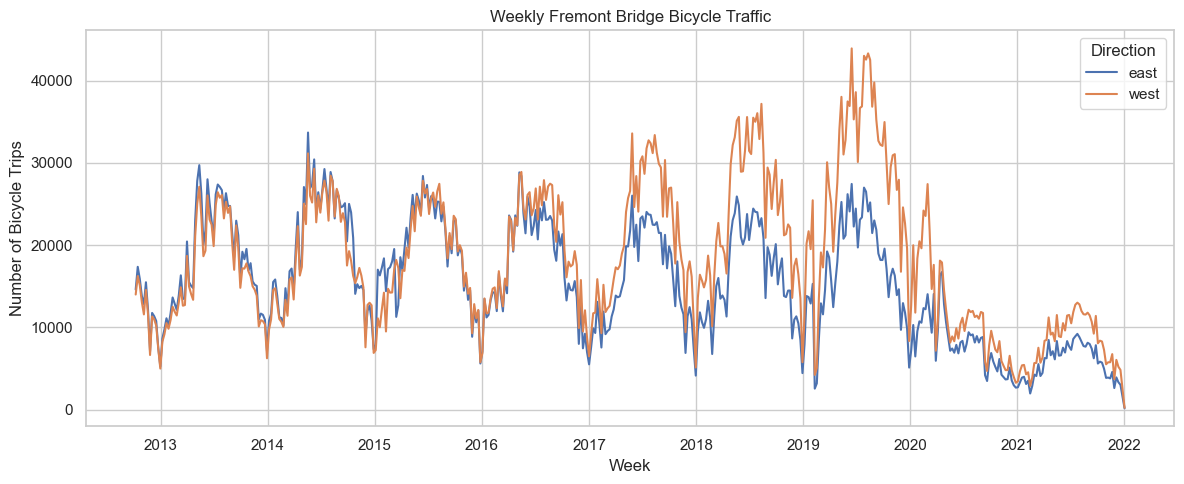

In [16]:
# Question 2a

# Calculate weekly bicycle counts for the two directions
weekly_bike_counts = bike_data[["east", "west"]].resample("W").sum()

# Create the visualization
plt.figure(figsize=(12, 5))

for column in weekly_bike_counts.columns:
    plt.plot(
        weekly_bike_counts.index,
        weekly_bike_counts[column],
        label=column
    )

plt.xlabel("Week")
plt.ylabel("Number of Bicycle Trips")
plt.title("Weekly Fremont Bridge Bicycle Traffic")
plt.legend(title="Direction")

plt.tight_layout()
plt.show()

---

## Question 2b — Interpret the Time Series

Using the weekly bicycle-traffic visualization above, describe the patterns you observe in terms of:

1. **Trend** — Is there evidence of a long-term increase or decrease in bicycle traffic?
2. **Seasonality** — Are there patterns that appear to repeat at regular times of the year?
3. **Cyclicity or unusual periods** — Are there longer-term changes or disruptions that do not appear to follow the regular seasonal pattern?

Support your interpretation using visible evidence from the plot.

**Q2b: Your answer:**

**Trend.** Traffic grew from late 2012 to a peak in 2019: the average weekly west-side count in the July–September quarter rose from about 22,700 (2013) to about 37,200 (2019). The east side stayed flatter, and the west side grew relative to it from about 2016 onward. In 2020 both directions fall sharply, and they stay low through 2021, well below the pre-2020 level.

**Seasonality.** Each year has the same shape: a low in winter (roughly 10,000 to 13,000 trips per week per direction), a rise through spring, a peak in summer, and a fall in autumn. The yearly cycle is clear in every year up to 2019, and it matches the weather and daylight hours that make cycling easier in summer.

**Cyclicity or unusual periods.** The 2020 to 2021 drop breaks the regular seasonal pattern. The spring and summer 2020 peak that would normally occur is missing, and weekly counts stay far below earlier summers. This is consistent with the COVID-19 pandemic, when commuting and downtown activity fell. Traffic stays suppressed through 2021 and does not return to the 2019 level. There is also a slight dip in 2017 on the east side that does not look seasonal.

---

So far, we have examined bicycle activity using time as contextual information.

We could continue by introducing additional variables such as weather, holidays, or day of the week. However, doing so would impose our own assumptions about which factors define different kinds of bicycle-traffic days.

Instead, we will ask the data a different question:

> **Can the hourly traffic pattern itself reveal different types of days?**

To investigate this, we need to represent each day as a single observation.

---

## Question 2c — Represent Each Day as a Feature Vector

The original dataset contains one row for each **hour**.

For our unsupervised learning analysis, we instead want one row for each **day**.

Each day contains:

- 24 hourly observations;
- for each of two travel directions.

Therefore, each day can be represented using **48 features**.

Create a DataFrame named `bike_data_features` where:

- each row represents one calendar day;
- the index is a `DatetimeIndex`;
- the columns represent combinations of hour and travel direction; and
- the values contain the corresponding bicycle counts.

Use `pivot_table()` to construct the DataFrame.

In [17]:
# Question 2c

# Keep only the two directional bicycle-count columns
direction_columns = ["east", "west"]

# Create a temporary DataFrame containing the directional counts
bike_data_daily = bike_data[direction_columns].copy()

# Extract the date and hour from the datetime index
bike_data_daily["date"] = bike_data_daily.index.normalize()
bike_data_daily["hour"] = bike_data_daily.index.hour

# Reshape the data so that each row represents one day
# and the columns represent direction-hour combinations
bike_data_features = bike_data_daily.pivot_table(
    index="date",
    columns="hour",
    values=direction_columns
)

# Create clear column names for the 48 features
bike_data_features.columns = [
    f"{direction}_hour_{hour:02d}"
    for direction, hour
    in bike_data_features.columns
]

bike_data_features.index.name = "date"

bike_data_features.head()

,east_hour_00,east_hour_01,east_hour_02,east_hour_03,east_hour_04,east_hour_05,east_hour_06,east_hour_07,east_hour_08,east_hour_09,...,west_hour_14,west_hour_15,west_hour_16,west_hour_17,west_hour_18,west_hour_19,west_hour_20,west_hour_21,west_hour_22,west_hour_23
date,,,,,,,,,,,,,,,,,,,,,
2012-10-03,4.0,4.0,1.0,2.0,6.0,21.0,105.0,257.0,291.0,172.0,...,51.0,92.0,182.0,391.0,258.0,69.0,51.0,38.0,25.0,12.0
2012-10-04,7.0,3.0,3.0,0.0,7.0,15.0,91.0,230.0,284.0,147.0,...,56.0,74.0,161.0,353.0,241.0,107.0,56.0,39.0,21.0,30.0
2012-10-05,4.0,4.0,4.0,2.0,7.0,18.0,68.0,218.0,251.0,131.0,...,62.0,84.0,190.0,290.0,209.0,73.0,41.0,31.0,26.0,16.0
2012-10-06,8.0,10.0,7.0,1.0,4.0,3.0,12.0,17.0,58.0,59.0,...,114.0,96.0,76.0,73.0,55.0,38.0,18.0,15.0,20.0,19.0
2012-10-07,6.0,12.0,2.0,4.0,1.0,6.0,9.0,14.0,43.0,67.0,...,115.0,109.0,93.0,73.0,45.0,23.0,36.0,35.0,9.0,11.0


In [18]:
# Verification - do not modify

print(
    "Q2c Answer - Number of daily observations:",
    bike_data_features.shape[0]
)

print(
    "Number of features per day:",
    bike_data_features.shape[1]
)

print(
    "Each day has 48 features:",
    bike_data_features.shape[1] == 48
)

print(
    "Index is a DatetimeIndex:",
    isinstance(
        bike_data_features.index,
        pd.DatetimeIndex
    )
)

Q2c Answer - Number of daily observations: 3376
Number of features per day: 48
Each day has 48 features: True
Index is a DatetimeIndex: True


---

## Question 2d — Fit PCA to Daily Bicycle-Traffic Patterns

Each day is currently represented by 48 features. We will use PCA to find a lower-dimensional representation of these daily traffic patterns.

Create a `PCA` object named `bike_pca` that computes all 48 principal components.

Fit the PCA model using `bike_data_features`.

In [19]:
# Question 2d

# Create a PCA model with one component for each feature
bike_pca = PCA(n_components=bike_data_features.shape[1])

# Fit the PCA model to the daily bicycle features
bike_pca.fit(bike_data_features)

print(
    "Number of PCA components:",
    bike_pca.n_components_
)

Number of PCA components: 48


In [20]:
# Verification - do not modify

print(
    "Q2d Answer - Number of components:",
    bike_pca.n_components_
)

print(
    "All 48 components computed:",
    bike_pca.n_components_ == 48
)

Q2d Answer - Number of components: 48
All 48 components computed: True


---
## Question 2e — Transform the Daily Traffic Data

Use the fitted `bike_pca` model to transform `bike_data_features` into principal-component space.

Store the transformed observations in a DataFrame named:

`bike_data_features_pcs`

The DataFrame should:

- have the same index as `bike_data_features`; and
- contain columns named `pc1`, `pc2`, ..., `pc48`.

In [21]:
# Question 2e

# Create names for the principal-component columns
pc_columns = [
    f"pc{i}"
    for i in range(
        1,
        bike_pca.n_components_ + 1
    )
]

# Transform the daily features into principal-component space
bike_data_features_pcs = pd.DataFrame(
    bike_pca.transform(bike_data_features),
    index=bike_data_features.index,
    columns=pc_columns
)

bike_data_features_pcs.head()

,pc1,pc2,pc3,pc4,pc5,pc6,pc7,pc8,pc9,pc10,...,pc39,pc40,pc41,pc42,pc43,pc44,pc45,pc46,pc47,pc48
date,,,,,,,,,,,,,,,,,,,,,
2012-10-03,263.913264,-42.974241,-88.538209,9.190823,36.624759,3.263648,16.189681,-6.162502,-27.785557,-15.270273,...,1.071371,-3.246276,-0.326677,1.324462,-0.631645,1.144061,-0.221562,2.126127,-1.132564,1.480500
2012-10-04,208.695226,-17.979818,-94.905471,6.446309,-12.449191,4.572520,14.713368,6.477409,-3.399848,-5.002281,...,3.575599,0.976940,-4.324217,-2.126936,-2.420368,1.123314,3.522190,0.848530,3.255609,0.520163
2012-10-05,130.066982,-8.023321,-75.519137,34.537501,24.570007,16.682786,-2.141930,-4.907896,-31.778911,13.778330,...,-2.772249,-0.718327,0.863490,0.379439,1.711419,2.367865,3.082111,1.280362,-0.647013,0.142505
2012-10-06,-289.306740,115.150808,-47.610677,17.776780,14.477558,-24.128231,-14.303265,-0.677926,-19.584010,-9.709990,...,-0.347493,2.152516,2.304878,-1.785851,-0.464539,5.872000,0.673785,0.571871,-3.022739,0.271468
2012-10-07,-298.369293,170.382391,-78.986336,20.141338,39.932704,-33.358718,-9.777606,11.347798,-18.302248,-14.936109,...,-1.927688,1.649803,2.963636,0.788745,1.003400,6.710750,-4.857664,1.533239,-1.697487,0.579656


In [22]:
# Verification - do not modify

print(
    "Q2e Answer - Correct shape:",
    bike_data_features_pcs.shape
    == bike_data_features.shape
)

print(
    "Index preserved:",
    bike_data_features_pcs.index.equals(
        bike_data_features.index
    )
)

print(
    "Correct first and last columns:",
    bike_data_features_pcs.columns[0] == "pc1"
    and bike_data_features_pcs.columns[-1] == "pc48"
)

Q2e Answer - Correct shape: True
Index preserved: True
Correct first and last columns: True


---

## Question 2f — Summarize Explained Variance

PCA orders the principal components according to how much variation they explain.

Using the fitted `bike_pca` model, create a DataFrame named `pca_summary`.

The DataFrame should contain:

- `Variance`
- `Proportion of Variance`
- `Cumulative Proportion`

as rows, with `PC1` through `PC48` as columns.

The cumulative proportion tells us how much of the total variation is retained when we keep the first several principal components.

In [23]:
# Question 2f

# Create column names for the PCA summary
pca_columns = [
    f"PC{i}"
    for i in range(
        1,
        bike_pca.n_components_ + 1
    )
]

# Summarize the variance explained by each principal component
pca_summary = pd.DataFrame(
    [
        bike_pca.explained_variance_,
        bike_pca.explained_variance_ratio_,
        np.cumsum(bike_pca.explained_variance_ratio_)
    ],
    index=[
        "Variance",
        "Proportion of Variance",
        "Cumulative Proportion"
    ],
    columns=pca_columns
)

pca_summary

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC39,PC40,PC41,PC42,PC43,PC44,PC45,PC46,PC47,PC48
Variance,108607.658023,12238.950053,7672.862789,1956.757280,1109.430596,766.986722,636.434125,434.982845,406.105068,341.275030,...,14.190712,7.647072,7.510872,6.806427,5.864098,4.211513,3.409182,2.946105,2.744521,1.645323
Proportion of Variance,0.791221,0.089162,0.055898,0.014255,0.008082,0.005588,0.004637,0.003169,0.002959,0.002486,...,0.000103,0.000056,0.000055,0.000050,0.000043,0.000031,0.000025,0.000021,0.000020,0.000012
Cumulative Proportion,0.791221,0.880384,0.936281,0.950537,0.958619,0.964207,0.968843,0.972012,0.974970,0.977457,...,0.999688,0.999744,0.999799,0.999848,0.999891,0.999922,0.999947,0.999968,0.999988,1.000000


In [24]:
# Verification - do not modify

print(
    "Q2f Answer - Correct shape:",
    pca_summary.shape == (3, 48)
)

print(
    "Final cumulative proportion:",
    round(
        pca_summary.loc[
            "Cumulative Proportion",
            "PC48"
        ],
        6
    )
)

Q2f Answer - Correct shape: True
Final cumulative proportion: 1.0


---

## Question 2g — Visualize Explained Variance

Create a plot showing the following quantities for the **first 10 principal components**:

- the proportion of variance explained by each individual component; and
- the cumulative proportion of variance explained.

Your plot should clearly distinguish the two quantities and include appropriate axis labels, a title, and a legend.

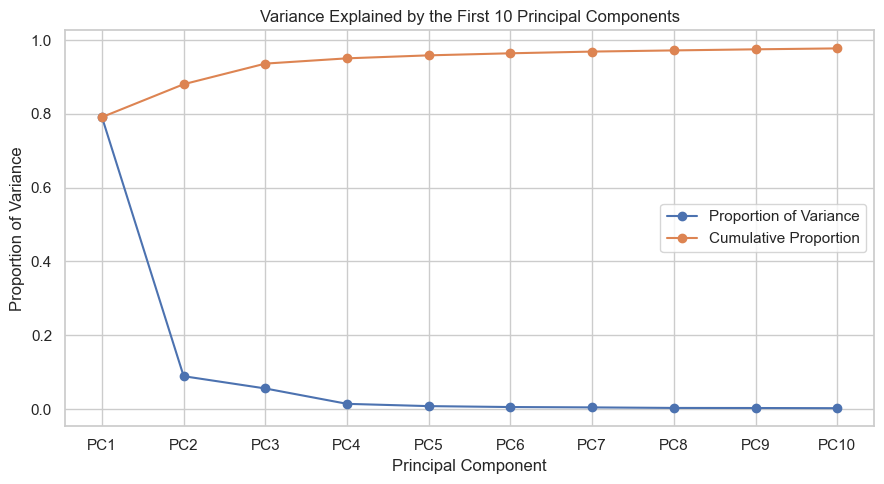

In [25]:
# Question 2g

# Select the first 10 principal components
first_10_components = pca_summary.iloc[:, :10]

plt.figure(figsize=(9, 5))

# Plot the proportion of variance explained
plt.plot(
    first_10_components.columns,
    first_10_components.loc["Proportion of Variance"],
    marker="o",
    label="Proportion of Variance"
)

# Plot the cumulative proportion of variance explained
plt.plot(
    first_10_components.columns,
    first_10_components.loc["Cumulative Proportion"],
    marker="o",
    label="Cumulative Proportion"
)

plt.xlabel("Principal Component")
plt.ylabel("Proportion of Variance")
plt.title("Variance Explained by the First 10 Principal Components")
plt.legend()

plt.tight_layout()
plt.show()

---

## Question 2h — Visualize Days in Principal-Component Space

The explained-variance results show that the first few principal components capture a large proportion of the variation in daily bicycle traffic.

We can therefore use the first two components to create a two-dimensional representation of the days.

Create a scatter plot with:

- `pc1` on the x-axis;
- `pc2` on the y-axis; and
- point colour representing the **total number of bicycle trips during that day**.

Store the daily totals in a Series named `total_trips`.

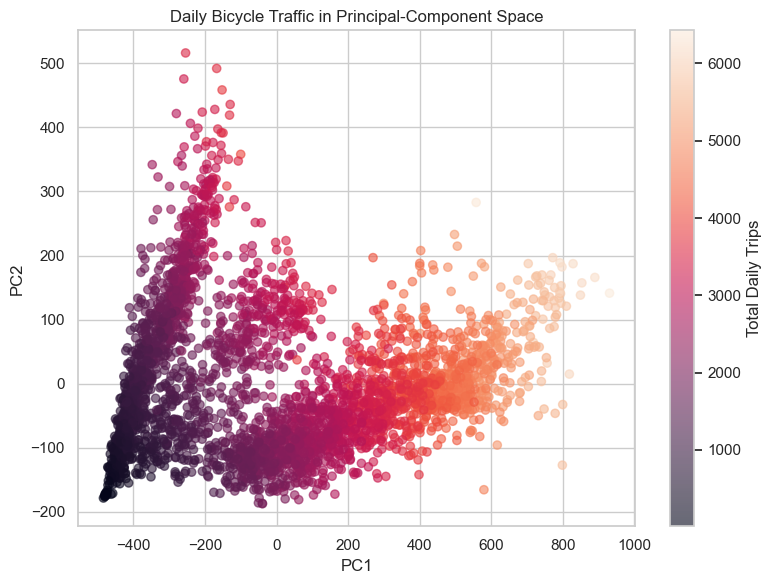

In [26]:
# Question 2h

# Calculate the total number of bicycle trips for each day
total_trips = bike_data_features.sum(axis=1)

plt.figure(figsize=(8, 6))

# Plot each day using the first two principal components
scatter = plt.scatter(
    bike_data_features_pcs["pc1"],
    bike_data_features_pcs["pc2"],
    c=total_trips,
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Daily Bicycle Traffic in Principal-Component Space")

plt.colorbar(
    scatter,
    label="Total Daily Trips"
)

plt.tight_layout()
plt.show()

The PCA visualization suggests that the days are not distributed uniformly in feature space.

Instead, several elongated groups appear to emerge. The position of a day within these groups is also associated with its total bicycle traffic.

This suggests that there may be multiple characteristic types of daily bicycle-traffic patterns.

We will now investigate those groups using clustering.

---
## Question 2i — Investigate the Number of Clusters

Clustering algorithms attempt to identify groups of similar observations without requiring predefined class labels.

We will begin with **k-means clustering**.

Fit k-means models using values of `k` from **1 through 10** using the first two principal components.

For each model, record its **inertia**, which measures the total squared distance between observations and their assigned cluster centres.

Use `random_state=0` and `n_init=10` so that the results are reproducible.

Store the inertia values in `kmeans_inertia` and create an elbow plot.

Based on the plot, we will investigate a four-cluster solution.


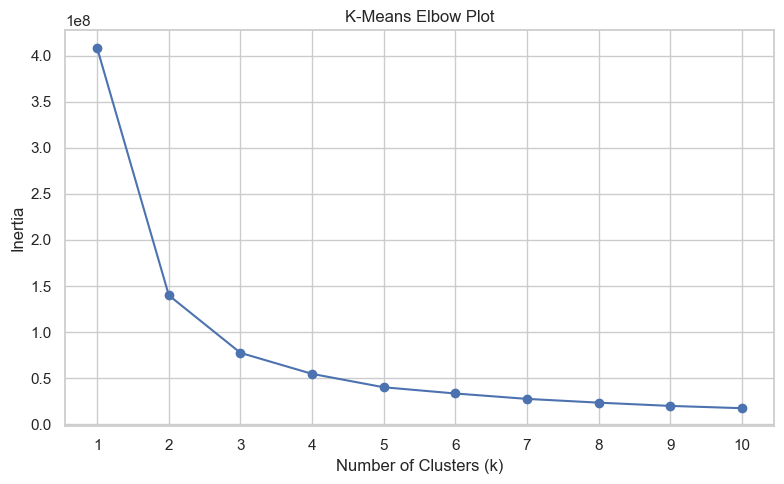

In [27]:
# Question 2i

# Use the first two principal components for clustering
X_cluster = bike_data_features_pcs[
    ["pc1", "pc2"]
]

# Values of k to investigate
cluster_counts = range(1, 11)

# Store the inertia from each fitted model
kmeans_inertia = []

for k in cluster_counts:
    
    # Fit a k-means model with k clusters
    kmeans_model = KMeans(n_clusters=k, random_state=0, n_init=10)
    
    kmeans_model.fit(X_cluster)
    
    # Store the model inertia
    kmeans_inertia.append(kmeans_model.inertia_)

# Plot inertia against the number of clusters
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_counts,
    kmeans_inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Plot")
plt.xticks(cluster_counts)

plt.tight_layout()
plt.show()

---

## Examining the K-Means Clusters

The elbow plot provides one diagnostic for selecting the number of clusters, but it does not guarantee that k-means is geometrically appropriate for the data.

We will examine a four-cluster solution in the PCA representation.

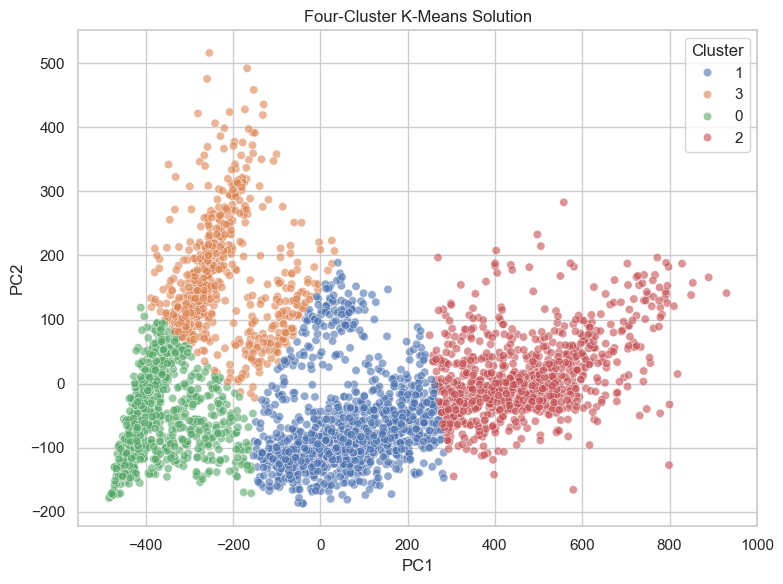

In [28]:
kmeans = KMeans(
    n_clusters=4,
    random_state=0,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(
    X_cluster
)

kmeans_plot_data = (
    X_cluster.copy()
)

kmeans_plot_data["cluster"] = (
    kmeans_labels.astype(str)
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=kmeans_plot_data,
    x="pc1",
    y="pc2",
    hue="cluster",
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Four-Cluster K-Means Solution")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

K-means assigns observations to the nearest cluster centre and therefore tends to work best when clusters are relatively compact and roughly spherical.

The groups visible in PCA space appear more **elongated** than spherical. This suggests that k-means may not capture their geometry particularly well.

We will therefore compare it with a **Gaussian Mixture Model (GMM)**, which can represent clusters with more flexible shapes.

---

## Clustering Using a Gaussian Mixture Model

Fit a four-component Gaussian Mixture Model to the same two-dimensional PCA representation.

We will use a full covariance matrix so that each component can model its own orientation and shape.

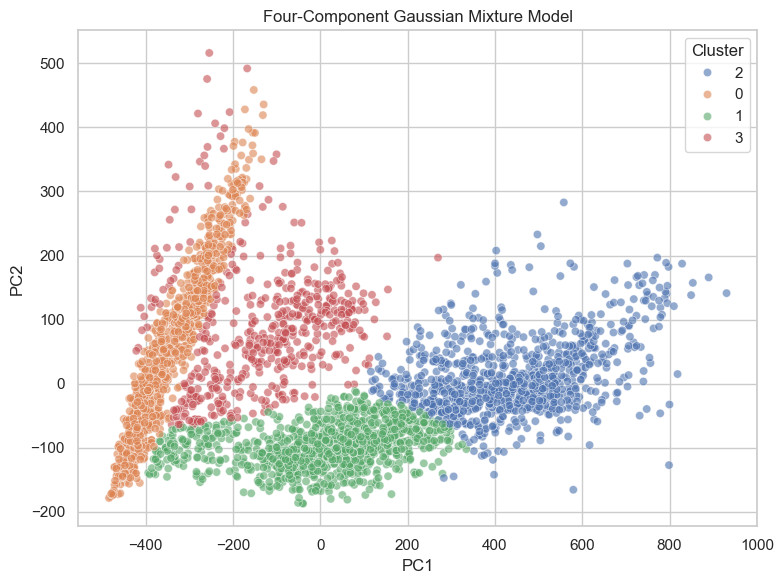

In [29]:
gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    random_state=0
)

gmm_labels = gmm.fit_predict(
    X_cluster
)

gmm_plot_data = (
    X_cluster.copy()
)

gmm_plot_data["cluster"] = (
    gmm_labels.astype(str)
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=gmm_plot_data,
    x="pc1",
    y="pc2",
    hue="cluster",
    alpha=0.6
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Four-Component Gaussian Mixture Model")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

---

## Interpreting the Clusters

Cluster labels such as `0`, `1`, `2`, and `3` have no inherent meaning.

To understand what the clusters represent, we need to return to the original hourly bicycle counts.

First, attach each day's GMM cluster label to the hourly dataset.

In [30]:
# Store the cluster assigned to each date
daily_clusters = pd.Series(
    gmm_labels,
    index=bike_data_features.index,
    name="cluster"
)

# Add a normalized date to the original hourly data
bike_data_clustered = bike_data.copy()

bike_data_clustered["date"] = (
    bike_data_clustered.index.normalize()
)

# Attach each day's cluster label
bike_data_clustered = (
    bike_data_clustered
    .join(
        daily_clusters,
        on="date"
    )
)

bike_data_clustered.head()

,total,east,west,date,cluster
datetime,,,,,
2019-11-01 00:00:00,12.0,7.0,5.0,2019-11-01,2
2019-11-01 01:00:00,7.0,0.0,7.0,2019-11-01,2
2019-11-01 02:00:00,1.0,0.0,1.0,2019-11-01,2
2019-11-01 03:00:00,6.0,6.0,0.0,2019-11-01,2
2019-11-01 04:00:00,6.0,5.0,1.0,2019-11-01,2


---

Next, calculate the average bicycle traffic for each **cluster and hour of the day**.

In [31]:
bike_data_clustered["hour"] = (
    bike_data_clustered.index.hour
)

cluster_hourly_profiles = (
    bike_data_clustered
    .groupby(
        ["cluster", "hour"]
    )[bike_data.columns]
    .mean()
)

cluster_hourly_profiles.head()

total      east      west
cluster hour                               
0       0     14.773311  6.077610  8.695701
        1      8.562814  3.819654  4.743160
        2      5.499721  2.505863  2.993858
        3      3.205472  1.581798  1.623674
        4      3.592965  1.484087  2.108878

The following visualization shows the average daily traffic profile for each of the four inferred clusters.

Look for differences in:

- morning traffic;
- evening traffic;
- direction of travel;
- total traffic volume; and
- whether traffic is concentrated around commuting hours or distributed more evenly throughout the day.

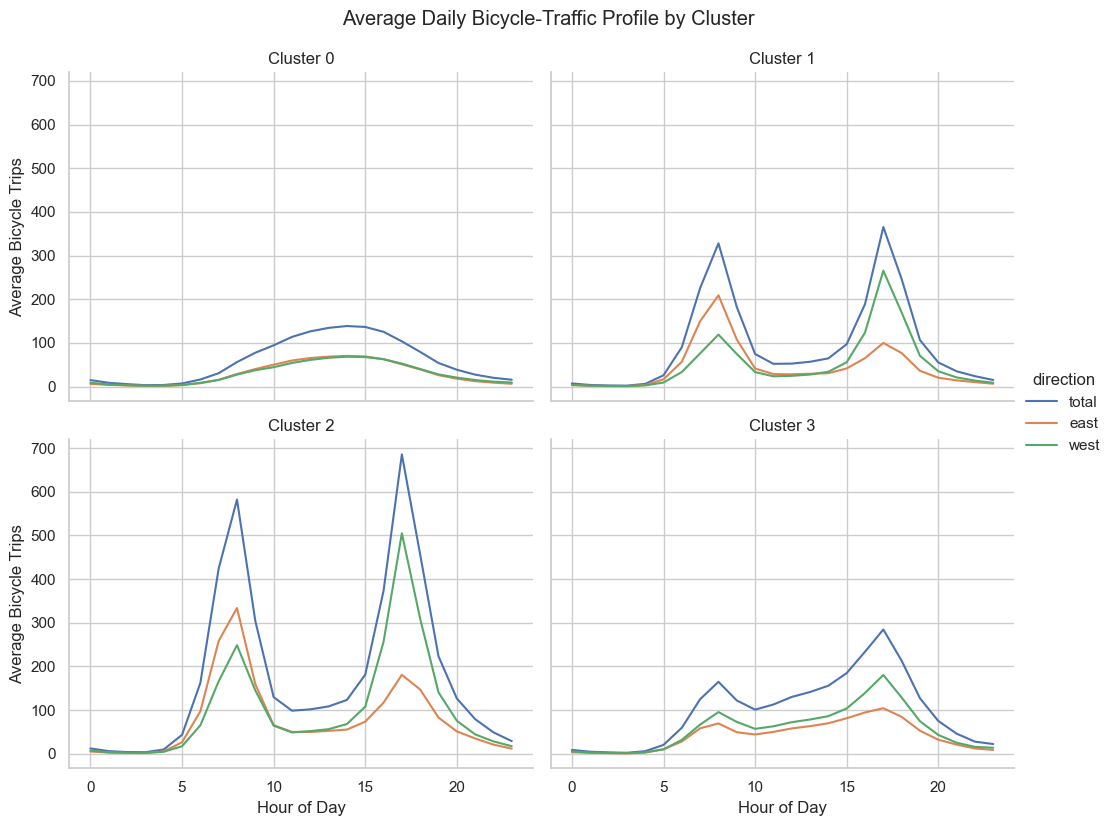

In [32]:
cluster_profile_plot = (
    cluster_hourly_profiles
    .reset_index()
    .melt(
        id_vars=[
            "cluster",
            "hour"
        ],
        var_name="direction",
        value_name="average_trips"
    )
)

g = sns.relplot(
    data=cluster_profile_plot,
    x="hour",
    y="average_trips",
    hue="direction",
    col="cluster",
    col_wrap=2,
    kind="line",
    height=4,
    aspect=1.3
)

g.set_axis_labels(
    "Hour of Day",
    "Average Bicycle Trips"
)

g.set_titles(
    "Cluster {col_name}"
)

g.figure.suptitle(
    "Average Daily Bicycle-Traffic Profile by Cluster",
    y=1.03
)

plt.show()

---
## Question 2j — Interpret the Discovered Traffic Patterns

Unsupervised learning has now given us a set of clusters, but the numerical cluster labels themselves do not tell us what the groups mean.

Use the original bicycle-traffic data and the dates associated with each cluster to interpret the patterns discovered by the Gaussian Mixture Model.

Create appropriate **visualizations and/or summary tables** to investigate the clusters.

Your analysis should address:

1. How does the hourly traffic pattern differ among the clusters?
2. Which clusters appear to show strong morning and evening commuting patterns?
3. Which clusters show bicycle activity distributed more evenly throughout the day?
4. How does overall bicycle traffic volume differ among the clusters?
5. Using the date index, are particular clusters associated with recognizable calendar patterns, such as weekdays, weekends, seasons, or unusual periods?

Conclude by giving each cluster a short descriptive interpretation based on the evidence you observe.

Remember that cluster numbers are arbitrary. Your interpretation should be based on the **observed characteristics of each cluster**, not the numerical label itself.

In [33]:
# Question 2j

# Add calendar information for interpreting the clusters
cluster_interpretation = pd.DataFrame({
    "cluster": daily_clusters,
    "total_trips": total_trips
})

cluster_interpretation["day_of_week"] = (
    cluster_interpretation.index.day_name()
)

cluster_interpretation["month"] = (
    cluster_interpretation.index.month_name()
)

cluster_interpretation.head()

,cluster,total_trips,day_of_week,month
date,,,,
2012-10-03,2,3521.0,Wednesday,October
2012-10-04,2,3475.0,Thursday,October
2012-10-05,2,3148.0,Friday,October
2012-10-06,0,2006.0,Saturday,October
2012-10-07,0,2142.0,Sunday,October


In [34]:
# Summarize traffic volume by cluster

cluster_summary = (
    cluster_interpretation
    .groupby("cluster")
    .agg(
        number_of_days=(
            "total_trips",
            "size"
        ),
        mean_daily_trips=(
            "total_trips",
            "mean"
        ),
        median_daily_trips=(
            "total_trips",
            "median"
        )
    )
)

cluster_summary.round(1)

,number_of_days,mean_daily_trips,median_daily_trips
cluster,,,
0,985,1456.1,1296.0
1,992,2259.7,2323.0
2,904,4311.7,4313.0
3,495,2365.4,2394.0


In [35]:
# Compare clusters with days of the week

cluster_by_day = pd.crosstab(
    cluster_interpretation["day_of_week"],
    cluster_interpretation["cluster"],
    normalize="columns"
)

day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

cluster_by_day = (
    cluster_by_day
    .reindex(day_order)
)

cluster_by_day.round(3)

cluster,0,1,2,3
day_of_week,,,,
Monday,0.036,0.196,0.191,0.162
Tuesday,0.014,0.202,0.210,0.158
Wednesday,0.009,0.184,0.218,0.190
Thursday,0.019,0.209,0.200,0.154
Friday,0.020,0.208,0.180,0.190
Saturday,0.450,0.001,0.000,0.077
Sunday,0.452,0.001,0.000,0.071


**Q2j: Your answer:**

The hourly profiles, daily totals, and calendar information separate the four GMM clusters into four types of day. The cluster numbers themselves are arbitrary labels from the model.

| Cluster | Days | Mean daily trips | Hourly pattern | Calendar pattern | Interpretation |
|---|---|---|---|---|---|
| 0 | 985 | about 1,456 | Low, flat and spread across the day, with a single broad peak around 14:00 (about 70 trips per hour in each direction) and no morning/evening spikes | About 90% weekends (45% Saturday, 45% Sunday), spread across all months | **Weekend and holiday days**: recreational riding concentrated in the middle of the day |
| 1 | 992 | about 2,260 | Commute pattern, with a morning peak in the east direction at 08:00 (about 209) and an evening peak in the west direction at 17:00 (about 265) | Almost entirely weekdays (about 20% each), concentrated in November through March | **Winter commuter weekdays**: commuter rides, but with lower volume in colder, darker, wetter months |
| 2 | 904 | about 4,312 | Strongest commute pattern, with peaks of about 334 (east, 08:00) and 505 (west, 17:00) | Only weekdays, mostly May through September, and mostly 2013 to 2019 | **Summer commuter weekdays**: the highest volume days, with strong two-peak commuting |
| 3 | 495 | about 2,365 | Weak, broad profile with a small evening peak (about 180 west, 104 east at 17:00) and no strong morning peak | Mix of weekdays (422) and weekends (73), and mostly 2020 to 2021 (405 of 495 days) | **Pandemic-era days**: reduced commuting, with traffic spread more evenly and a flatter profile |

**Answers to the specific questions.**

1. The hourly shape differs the most between the commuter clusters (1 and 2, two sharp peaks), cluster 0 (one broad midday hump) and cluster 3 (low and flat with a small evening bump).
2. Clusters 1 and 2 show strong commuting. In both, the east direction peaks in the morning at 08:00 and the west direction peaks in the evening at 17:00, which suggests the typical commute is toward the city centre in the morning and home in the evening.
3. Cluster 0 (weekends) and cluster 3 (pandemic days) are distributed more evenly across the day, with no strong rush-hour peaks.
4. Volume order from highest to lowest is: cluster 2 (about 4,312 trips per day), cluster 3 (about 2,365), cluster 1 (about 2,260), and cluster 0 (about 1,456). Cluster 2 has roughly three times the volume of a weekend day.
5. The date index shows recognisable calendar structure even though the model never saw dates: weekends fall almost entirely in cluster 0, summer weekdays in cluster 2, winter weekdays in cluster 1, and 2020 to 2021 in cluster 3.

**Conclusion.** Using only the hourly counts, PCA plus a Gaussian mixture model recovered weekday versus weekend behaviour, a seasonal split among commuter days, and the change in behaviour during the pandemic. The GMM handles the elongated groups in PC space better than k-means, which would cut across them with straight boundaries.

---

cluster,0,1,2,3
year,,,,
2012,30,56,4,0
2013,108,159,88,10
2014,108,133,112,12
2015,104,126,111,24
2016,110,135,118,3
2017,107,131,117,10
2018,105,98,150,12
2019,106,54,186,19
2020,102,52,18,194


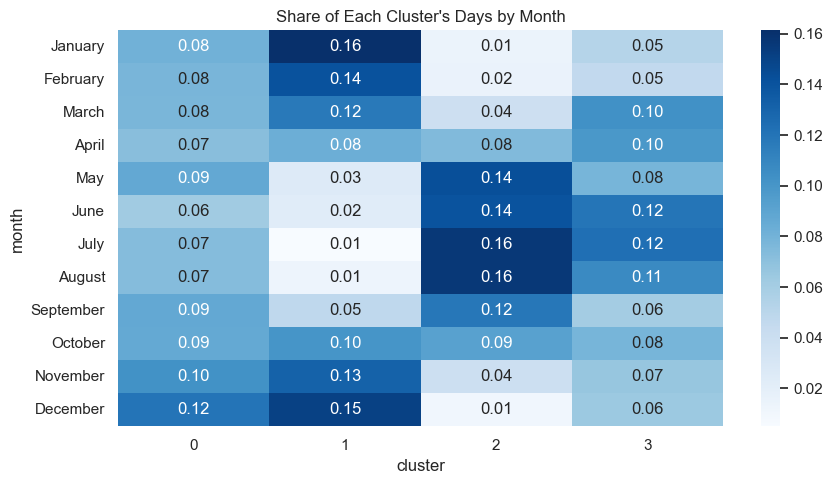

In [36]:
# Optional additional analysis for Question 2j

# Number of days in each cluster by year
cluster_by_year = pd.crosstab(
    cluster_interpretation.index.year,
    cluster_interpretation["cluster"]
)
cluster_by_year.index.name = "year"
display(cluster_by_year)

# Share of each cluster's days that fall in each month
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

cluster_by_month = (
    pd.crosstab(
        cluster_interpretation["month"],
        cluster_interpretation["cluster"],
        normalize="columns"
    )
    .reindex(month_order)
)

plt.figure(figsize=(9, 5))
sns.heatmap(cluster_by_month, annot=True, fmt=".2f", cmap="Blues")
plt.title("Share of Each Cluster's Days by Month")
plt.tight_layout()
plt.show()

---

# Submission

Before submitting your assignment:

1. Restart the kernel and run all cells from beginning to end to make sure the notebook executes without errors.
2. Save your completed notebook (`.ipynb`) and submit it to **Quercus**.
3. Push your completed assignment to your **GitHub repository**.

Make sure your final notebook contains only the required code, outputs, figures, and written responses.